In [1]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar

start_scope()

DATA_PATH = Path('data') 
n_rc=14
pattern_duration = 1000*ms
num_patterns = 12
# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800


# AMPA
g_AMPA_ext_E = 20.8 * nS #2.08
g_AMPA_rec_E = 0.104 * nS 
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS 
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 1.25*nS #1.25 * nS 0.8
g_GABA_I = 1.25*nS #0.973 * nS 0.8
tau_GABA = 10. * ms


#STDP/iSTDP
Apre = 0.012
Apost = -0.0115 
w_max = 1.5 #3


# Apre_i = -0.005   
# Apost_i = 0.005
Apre_i = -0.011   
Apost_i = 0.015
w_max_i = 5.0

#gif 
# save_interval = 0.1*second  
# frames = []

# def plot_weights_for_gif(t):
#     conn_data = C_PG_E.get_states(['i', 'j', 'w'])  
#     n_inputs = np.max(conn_data['i']) + 1
#     n_outputs = np.max(conn_data['j']) + 1
#     W = np.zeros((n_inputs, n_outputs))

#     for i, j, w_ij in zip(conn_data['i'], conn_data['j'], conn_data['w']):
#         W[i, j] = w_ij

#     plt.figure(figsize=(6, 6))
#     plt.imshow(W, cmap='hot', interpolation='nearest')
#     plt.title(f'Synaptic Weights at t = {t/ms:.0f} ms')
#     plt.colorbar(label='Weight')
#     plt.xlabel('Post-synaptic neuron')
#     plt.ylabel('Pre-synaptic neuron')

#     frame = plt.gcf()
#     frames.append(frame)
#     plt.close()

def create_mexican_hat_kernel():
    from scipy.ndimage import gaussian_filter
    center = np.zeros((3,3))
    center[1,1] = 1.0
    g1 = gaussian_filter(center, sigma=0.5)
    g2 = gaussian_filter(center, sigma=1.0)
    return g1 - g2
kernel = create_mexican_hat_kernel() 


def apply_mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered


def generate_bar_image(shape=(n_rc, n_rc), n_bars=3):
    img = np.zeros(shape, dtype=np.float32)
    orientation = np.random.choice(['horizontal', 'vertical', 'diagonal'])

    for _ in range(n_bars):
        if orientation == 'horizontal':
            row = np.random.randint(1, shape[0]-1)
            img[row, :] = 1.0
        elif orientation == 'vertical':
            col = np.random.randint(1, shape[1]-1)
            img[:, col] = 1.0
        elif orientation == 'diagonal':
            shift = np.random.randint(-shape[0]//2, shape[0]//2)
            for i in range(shape[0]):
                j = i + shift
                if 0 <= j < shape[1]:
                    img[i, j] = 1.0
    return img


def mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered

def convert_to_rates(filtered_img, max_rate=50):
    norm_img = filtered_img - np.min(filtered_img)
    norm_img /= np.max(norm_img)
    rates = norm_img.flatten() * max_rate * Hz
    return rates

def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)

def build_network(training):
    # variables
    n_input_rows = n_rc-2  
    n_input_columns = n_rc-2  
    n_output_rows = n_rc-4  
    n_output_columns = n_rc-4  
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    N_I = int(N_inp * 0.2)  
    target_rate = 5*Hz
    alpha = 0.05 #0.1
    window = 1*second
    plasticity_dt = 100*ms
    max_gate = 3

    # voltage
    V_L = -70. * mV
    V_thr = -50. * mV
    V_reset = -55. * mV
    V_E = 0.0 * mV
    V_I = -70. * mV

    # membrane capacitance
    C_m_E = 0.5 * nF
    C_m_I = 0.2 * nF

    # membrane leak
    g_m_E = 25. * nS
    g_m_I = 20. * nS

    # refractory period
    tau_rp_E = 2. * ms
    tau_rp_I = 1. * ms

    # external stimuli
    rate = 3 * Hz
    C_ext = 800

    # synapses
    C_E = N_E
    C_I = N_I

    # AMPA
    g_AMPA_ext_E = 20.8 * nS #2.08
    g_AMPA_rec_E = 0.104 * nS 
    g_AMPA_ext_I = 1.62 * nS
    g_AMPA_rec_I = 0.081 * nS 
    tau_AMPA = 2. * ms


    # GABAa
    g_GABA_E = 1.25*nS #1.25 * nS 
    g_GABA_I = 1.25*nS #0.973 * nS 
    tau_GABA = 10. * ms


    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
    I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1
    '''

    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
    I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1
    '''

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
    P_I.v = V_L

    #STDP
    stdp_eqs = '''
    w : 1
    dpre/dt = -pre/ taupre : 1 (event-driven)
    dpost/dt = -post/ taupost : 1 (event-driven)
    taupre : second (constant)
    taupost : second (constant)
    '''


    on_pre_stdp = '''
    s_AMPA += w
    pre += 1.
    w = clip(w + Apost * post, 0, w_max)
    '''

    on_post_stdp = '''
    post += 1.
    w = clip(w + Apre * pre, 0, w_max)
    '''
    #iSTDP
    iSTDP_eqs = '''
    w : 1
    dpre/dt = -pre / taupre : 1 (event-driven)
    dpost/dt = -post / taupost : 1 (event-driven)
    taupre : second (constant)
    taupost : second (constant)
    '''

    on_pre_iSTDP = '''
    s_GABA += w
    pre += 1.
    w = clip(w + Apost_i * post, 0, w_max_i)
    '''

    on_post_iSTDP = '''
    post += 1.
    w = clip(w + Apre_i * pre, 0, w_max_i)
    '''


    #E1
    # E to E
    C_E_E = Synapses(P_E, P_E,
                    model=stdp_eqs,
                    on_pre=on_pre_stdp,
                    on_post=on_post_stdp,
                    method='euler',
                    name='E_E')
    #C_E_E.connect('i != j')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)

    C_E_E.taupre = 10*ms
    C_E_E.taupost = 10*ms

    # E to I
    C_E_I = Synapses(P_E, P_I,
                    model=stdp_eqs,
                    on_pre=on_pre_stdp,
                    on_post=on_post_stdp,
                    method='euler',
                    name='E_I')
    C_E_I.connect()
    C_E_I.taupre = 20*ms
    C_E_I.taupost = 20*ms

    # I to I
    C_I_I = Synapses(P_I, P_I,
                    model=iSTDP_eqs,
                    on_pre=on_pre_iSTDP,
                    on_post=on_post_iSTDP,
                    method='euler',
                    name='I_I')
    C_I_I.connect('i != j')
    C_I_I.taupre = 20*ms
    C_I_I.taupost = 20*ms

    # I to E
    C_I_E = Synapses(P_I, P_E,
                    model=iSTDP_eqs,
                    on_pre=on_pre_iSTDP,
                    on_post=on_post_iSTDP,
                    method='euler',
                    name='I_E')
    C_I_E.connect()
    C_I_E.taupre = 20*ms
    C_I_E.taupost = 20*ms

    #pattern
    #pg_inp = PoissonGroup(N_inp, rates='input_rate_timed(t, i) * Hz', name = 'inp')
    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
            s_AMPA_ext += w
            pre += 1.
            w = clip(w + Apost * post, 0, 100)
        ''',
        on_post='''
            post += 1.
            w = clip(w + Apre * pre, 0, 100)
        ''',
        method='euler', name='PG_E')
    C_PG_E.connect(False)  

    rf_size = 3  
    half_rf = rf_size // 2


    for out_y in range(n_output_rows):
        for out_x in range(n_output_columns):
            out_index = out_y * n_output_columns + out_x  
            for dx in range(3):  
                for dy in range(3):
                    in_x = out_x + dx
                    in_y = out_y + dy
                    if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                        in_index = in_y * n_input_columns + in_x  
                        C_PG_E.connect(i=in_index, j=out_index)       
                        print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
             

    C_PG_E.taupre = 10*ms
    C_PG_E.taupost = 10*ms
    if training:
        C_PG_E.w[:] = 1
        C_I_E.w[:] = 1
        C_I_I.w[:] = 1
        C_E_I.w[:] = 1
        C_E_E.w[:] = 1
    else:
        w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = w_PG_E
        C_I_E.w[:] = w_I_E
        C_I_I.w[:] = w_I_I
        C_E_I.w[:] = w_E_I
        C_E_E.w[:] = w_E_E

    # external noise
    #C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
    C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')


    # monitors

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')

    r_E = PopulationRateMonitor(P_E)
    r_I = PopulationRateMonitor(P_I)

    # mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
    mon_C_PG_E = StateMonitor(C_E_E, 'w', record=True)

    # mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
    # mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
    # mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)


    # @network_operation(dt=save_interval)
    # def capture_frames():
    #     plot_weights_for_gif(defaultclock.t)


    # @network_operation(dt=plasticity_dt)
    # def homeostatic_plasticity():
    #     t_now = defaultclock.t
    #     if t_now < window:
    #         return
    #     t0 = t_now - window
    #     #E
    #     times = sp_E.t
    #     idxs  = sp_E.i
    #     rates = np.zeros(N_E)*Hz
    #     for post in range(N_E):
    #         mask = np.logical_and(idxs == post, times >= t0)
    #         count = np.sum(mask)
    #         rates[post] = count/window
    #         delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
    #         for pre in range(N_E):
    #             if pre == post:
    #                 continue
    #             C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 5)
    #         for pre in range(N_I):
    #             C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 5)
    #         for pre in range(N_I):
    #             C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, 5)
    #     print(f"[{t_now/ms:.0f} ms]  "
    #           f"rates (mean): {np.mean(rates):.1f} Hz  ")  
    #     #I
    #     times1 = sp_E.t
    #     idxs1  = sp_E.i
    #     rates1 = np.zeros(N_E)*Hz
    #     rates2 = np.zeros(N_E)*Hz
    #     for post in range(N_E):  
    #         mask1 = np.logical_and(idxs1 == post, times1 >= t0)
    #         count1 = np.sum(mask1)
    #         rates1[post] = count1 / window
    #     avg_rate_E = np.mean(rates1) 
    #     C_I_I.w[:] = clip(C_I_I.w[:] - alpha * (avg_rate_E - target_rate) / target_rate, 0, 5)

    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net


def show_img(net):
    img=generate_bar_image((n_rc, n_rc), 3)
    rate_img=convert_to_rates(mexican_hat(img))
    net['inp'].rates = rate_img
    net.run(500*ms)
    net['inp'].rates = 5 * Hz
    net.run(500 * ms)
    net['inp'].rates = 0 * Hz
    net.run(500 * ms)

def train(N_train):
    net = build_network(True)
    for i in range(N_train): #progressbar(
        show_img(net)
        print(i)

    save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
    save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
    save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
    save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
    save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
    return net

def test():
    net = build_network(False)



INFO       Cache size for target 'cython': 1192 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


INFO:root:creating /tmp/brian_flag_test_lut1s5w3/tmp
INFO:root:creating /tmp/brian_flag_test_lut1s5w3/tmp/brian_flag_test_lut1s5w3
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_lut1s5w3/flag_test.cpp -o /tmp/brian_flag_test_lut1s5w3/tmp/brian_flag_test_lut1s5w3/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_70hajhj0/tmp
INFO:root:creating /tmp/brian_flag_test_70hajhj0/tmp/brian_flag_test_70hajhj0
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_70hajhj0/flag_test.cpp -o /tmp/brian_flag_test_70hajhj0/tmp/brian_flag_test_70hajhj0/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_tza759_5/tmp
INFO:root:creating /tmp/brian_flag_test_tza759_5/tmp/brian_flag_test_tza759_5
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_tza759_5/flag_test.cpp -o /tmp/brian_flag_test_tz

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

WARNING    'post' is an internal variable of group 'E_E', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'pre' is an internal variable of group 'E_E', but also exists in the run namespace with the value 98. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'post' is an internal variable of group 'E_I', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'pre' is an internal variable of group 'E_I', but also exists in the run namespace with the value 98. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'post' is an internal variable of group 'I_E', but also exists in the run namespace with the value 99. The internal variable will be used. [brian2.groups.group.Group.r

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
Saving (900,) data/w_PG_E.npy
Saving (1836,) data/w_E_E.npy
Saving (2800,) data/w_I_E.npy
Saving (2800,) data/w_E_I.npy
Saving (756,) data/w_I_I.npy


WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



<Axes: xlabel='time (s)', ylabel='neuron index'>

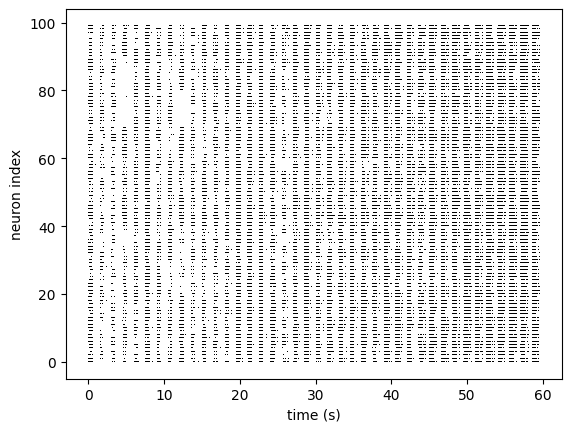

In [2]:
net = train(40)
exc_mon = net['sp_exc']
#inh_mon=net['sp_inh']
plot_raster(exc_mon.i, exc_mon.t, time_unit=second, marker=',', color='k')
#plot_raster(inh_mon.i, inh_mon.t, time_unit=second, marker=',', color='k')

<Axes: xlabel='time (s)', ylabel='neuron index'>

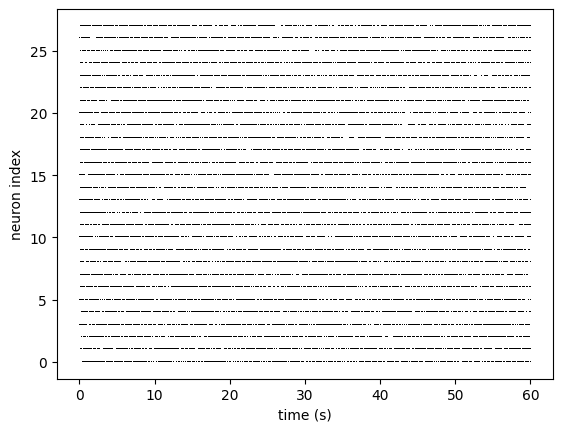

In [3]:
inh_mon=net['sp_inh']
plot_raster(inh_mon.i, inh_mon.t, time_unit=second, marker=',', color='k')